In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, ParameterGrid, cross_validate, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

1: handwritten, see the photo below (also p1.jpg in this folder).

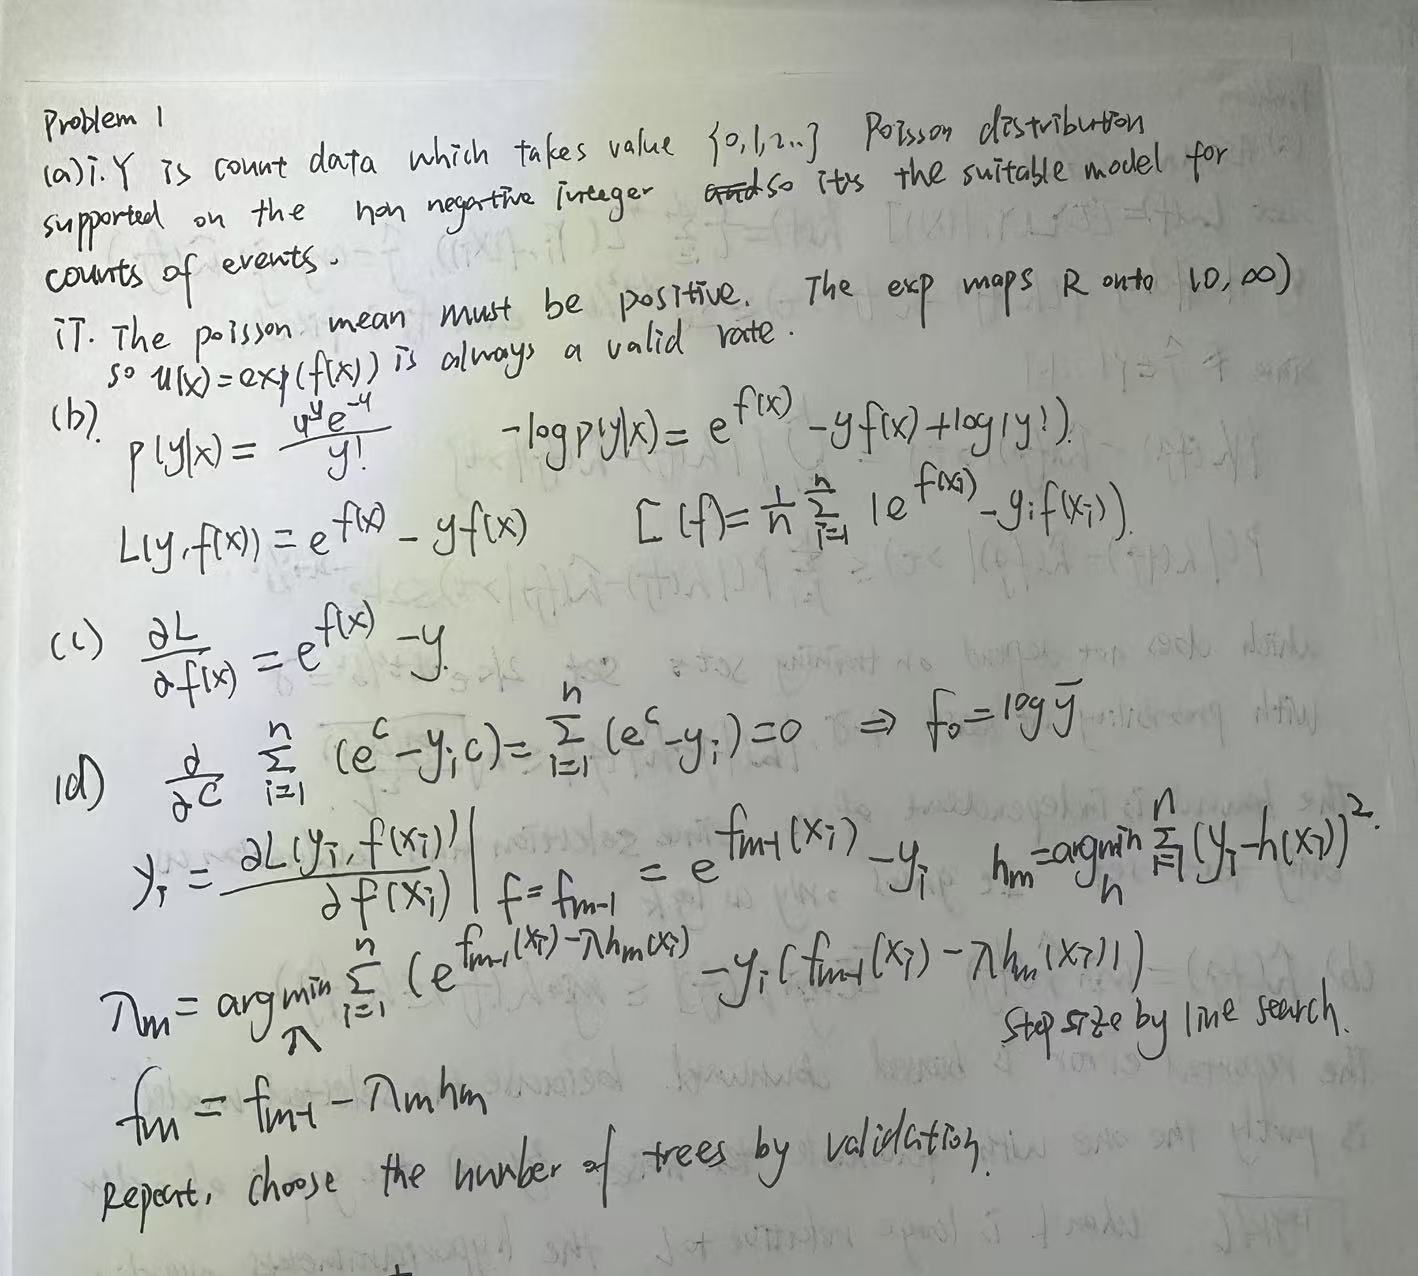

2(a), 2(b): handwritten, see the photo below (also p2ab.jpg in this folder).

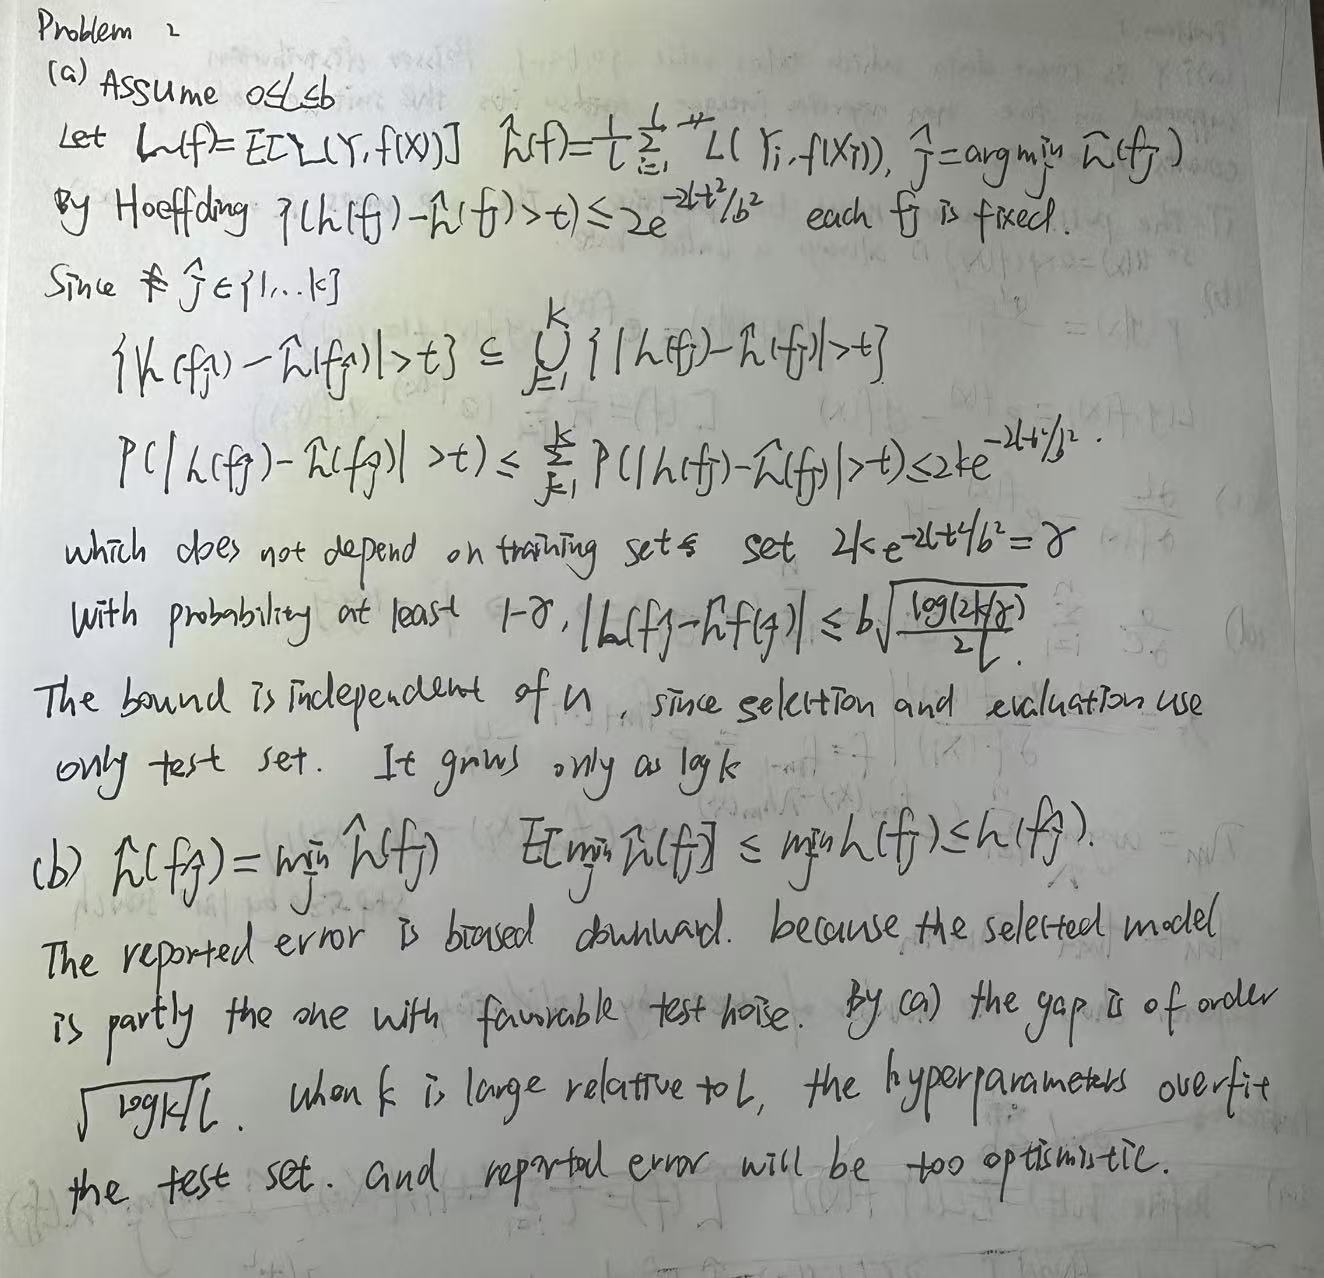

2(c)

In [2]:
d=pd.read_csv('wine+quality/winequality-white.csv',sep=';')
X = d.drop(columns='quality').values
y=d['quality'].values
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.2,random_state=0)
Xtr, Xva,ytr,yva = train_test_split(Xtr,ytr,test_size=0.125, random_state=0)
print(len(ytr),len(yva),len(yte))
sc=StandardScaler().fit(Xtr)
Xtr,Xva,Xte = sc.transform(Xtr),sc.transform(Xva),sc.transform(Xte)

def search(M,grid):
    va,te,ps=[],[],[]
    for p in ParameterGrid(grid):
        m=M(**p).fit(Xtr,ytr)
        va.append(np.mean((m.predict(Xva)-yva)**2))
        te.append(np.mean((m.predict(Xte)-yte)**2))
        ps.append(p)
    va,te=np.array(va),np.array(te)
    i=np.argmin(va)
    print('n settings',len(ps))
    print('best',ps[i])
    print('val mse',va[i],'test mse',te[i])
    print('corr val/test over all settings',np.corrcoef(va,te)[0,1])
    print('mean test-val over all settings', np.mean(te-va))

3428 490 980


In [3]:
search(KNeighborsRegressor,{'n_neighbors':range(1,101),'weights':['uniform','distance'],'p':[1,2,3]})

n settings 600
best {'n_neighbors': 12, 'p': 1, 'weights': 'distance'}
val mse 0.3807922507337445 test mse 0.4962322078029024
corr val/test over all settings 0.9619600333243964
mean test-val over all settings 0.10955422767887432


In [4]:
search(RandomForestRegressor, {'n_estimators':[50,100],'max_depth':[None,5,10,15,20,25],'min_samples_leaf':[1,2,4,8],
 'max_features':[0.2,0.4,0.6,1.0],'min_samples_split':[2,5,10],'random_state':[0],'n_jobs':[-1]})

n settings 576
best {'max_depth': None, 'max_features': 0.2, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100, 'n_jobs': -1, 'random_state': 0}
val mse 0.37543163265306123 test mse 0.4680289795918367
corr val/test over all settings 0.991360062631658
mean test-val over all settings 0.1014881052729268


70/10/20 split (3428/490/980), features standardized, MSE loss. KNN: 600 settings, RF: 576 settings (both > 490 val points).
KNN: k = number of neighbors averaged, p = distance type, weights = closer neighbors count more or not. RF: number of trees, tree depth, min leaf size, min split size, fraction of features tried at each split.

- KNN best (k=12, p=1, distance): val MSE 0.381, test MSE 0.496
- RF best (100 trees, max_features=0.2): val MSE 0.375, test MSE 0.468

Val and test MSE are highly correlated over all settings (0.96, 0.99), so val picks good settings. But the best val MSE is lower than its test MSE. Part of this is because we took the min over 500+ settings on the same val set, so it's optimistic. Part is that this val split is a bit easier (test - val is about 0.1 for all settings). The test MSE is the honest estimate.

3(a)

In [5]:
def boost(f):
    d=pd.read_csv(f,header=None)
    y=d[0].values
    X = d.iloc[:,1:].values
    for n in [1,10,100,300,1000]:
        r=cross_validate(GradientBoostingClassifier(n_estimators=n,random_state=0),X,y,cv=5,return_train_score=True)
        print(n,'trees  train acc',round(r['train_score'].mean(),3),' test acc', round(r['test_score'].mean(),3))

boost('dset0-1.csv')

1 trees  train acc 0.574  test acc 0.574
10 trees  train acc 0.846  test acc 0.746


100 trees  train acc 0.995  test acc 0.828


300 trees  train acc 1.0  test acc 0.83


1000 trees  train acc 1.0  test acc 0.826


Train acc reaches 1.0, but test acc goes up until 300 trees (0.57, 0.75, 0.83, 0.83) and stays about the same at 1000 (0.83). No real overfitting.

3(b)

In [6]:
boost('dset1-1.csv')

1 trees  train acc 0.675  test acc 0.656
10 trees  train acc 0.872  test acc 0.804


100 trees  train acc 0.986  test acc 0.82


300 trees  train acc 1.0  test acc 0.808


1000 trees  train acc 1.0  test acc 0.798


Test acc 0.66, 0.80, 0.82, 0.81, 0.80. Best at 100 trees, then drops. Overfits.

3(c)

In [7]:
for f in ['dset0-1.csv','dset1-1.csv']:
    d=pd.read_csv(f,header=None)
    print(f,'logistic reg test acc',cross_val_score(LogisticRegression(max_iter=1000),d.iloc[:,1:].values,d[0].values,cv=5).mean().round(3))
    print(d[0].groupby(pd.cut(d[1],[-4,-1.5,-0.5,0.5,1.5,4]),observed=True).mean().round(2))

dset0-1.csv logistic reg test acc 0.64
1
(-4.0, -1.5]    0.28
(-1.5, -0.5]    0.57
(-0.5, 0.5]     0.29
(0.5, 1.5]      0.60
(1.5, 4.0]      0.20
Name: 0, dtype: float64
dset1-1.csv logistic reg test acc 0.824
1
(-4.0, -1.5]    0.97
(-1.5, -0.5]    0.78
(-0.5, 0.5]     0.42
(0.5, 1.5]      0.11
(1.5, 4.0]      0.00
Name: 0, dtype: float64


dset1 is close to linear (logistic regression gets 0.82, same as boosting), so the rest is label noise and extra trees just fit noise. dset0 is more complex (P(y=1) goes up and down with the first feature, logistic only 0.64), so more trees keep learning real structure.